### **People Detection with HOG and a Linear SVM**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jrafa1607/Computer_Vision_In_Python/blob/main/Algorithms/HOG_SVM_People_Detection.ipynb)

> The **Histogram of Oriented Gradients (HOG)** describes a window by the distribution of edge directions in small cells. OpenCV ships a **linear SVM** trained on HOG features of pedestrians (Dalal and Triggs, 2005). Sliding a 64×128 window over the image at several scales detects people; **non-maximum suppression** removes overlapping boxes.

In [1]:
# Import libraries and helpers (images load from ../Images locally, or from GitHub in Colab)
import os
import urllib.request

import cv2
import numpy as np
from matplotlib import pyplot as plt

BASE_URL = "https://raw.githubusercontent.com/jrafa1607/Computer_Vision_In_Python/main/Images/"

def load_image(name, flags=cv2.IMREAD_COLOR):
    """Returns the image in OpenCV format (BGR for color images)."""
    local = os.path.join("..", "Images", name)
    if os.path.exists(local):
        data = np.fromfile(local, np.uint8)
    else:
        with urllib.request.urlopen(BASE_URL + name) as response:
            data = np.frombuffer(response.read(), np.uint8)
    return cv2.imdecode(data, flags)

def show(images, titles, size=(14, 4)):
    """Shows images side by side; color images are converted from BGR to RGB for Matplotlib."""
    fig, axes = plt.subplots(1, len(images), figsize=size)
    for ax, image, title in zip(np.atleast_1d(axes), images, titles):
        if image.ndim == 3:
            ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(image, cmap="gray", vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

#### **How HOG Works**

1. **Gradients:** magnitude and direction of the intensity change at every pixel.
2. **Cells:** the window is split into 8×8-pixel cells; each cell builds a 9-bin histogram of gradient directions weighted by magnitude.
3. **Block normalization:** histograms of 2×2 cells are normalized together, which reduces the effect of lighting and contrast.
4. **Descriptor:** all block histograms are concatenated (3,780 values for a 64×128 window) and scored by the SVM.

In [2]:
# Load the image and the pretrained people detector
img = load_image("Running.png")
hog = cv2.HOGDescriptor()
hog.setSVMDetector(cv2.HOGDescriptor_getDefaultPeopleDetector())
print("Descriptor length per 64x128 window:", hog.getDescriptorSize())

Descriptor length per 64x128 window: 3780


Raw detections: 2 | after NMS: 2


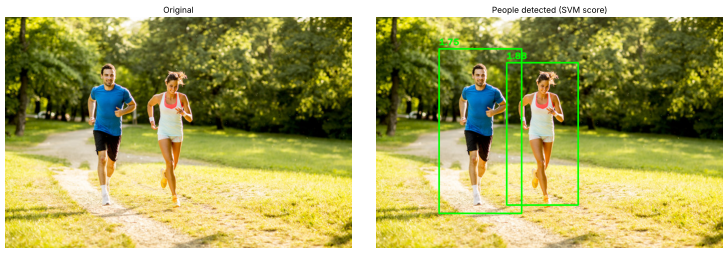

In [3]:
# Detect people at several scales and keep the best non-overlapping boxes
boxes, weights = hog.detectMultiScale(img, winStride=(4, 4), padding=(8, 8), scale=1.05)
weights = np.ravel(weights).tolist()
keep = np.array(cv2.dnn.NMSBoxes([list(map(int, b)) for b in boxes], weights, 0.5, 0.3)).ravel() if len(boxes) else []

result = img.copy()
for i in keep:
    x, y, w, h = boxes[i]
    cv2.rectangle(result, (x, y), (x + w, y + h), (0, 255, 0), 2)
    cv2.putText(result, f"{weights[i]:.2f}", (x, y - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
print(f"Raw detections: {len(boxes)} | after NMS: {len(keep)}")
show([img, result], ["Original", "People detected (SVM score)"], size=(15, 5))

#### **Key Takeaways**

* HOG + linear SVM is fast and needs no GPU, but it works best for upright, fully visible people at least 64×128 pixels tall.
* `winStride` and `scale` trade speed for recall; NMS removes duplicate boxes.
* Modern detectors (for example, YOLO) are far more accurate for occlusion, unusual poses, and small people.